In [13]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
import seaborn as sns
import math
from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit

In [2]:
rcParams.update({'figure.autolayout': True})
file_location = os.path.join('C:\\Users\\Austin\\Desktop\\cell_model\\07-03-22', 'AKTERKFAK*total.csv')
filenames = glob.glob(file_location)

In [3]:
filenames

['C:\\Users\\Austin\\Desktop\\cell_model\\07-03-22\\AKTERKFAK_030_020_040_total.csv',
 'C:\\Users\\Austin\\Desktop\\cell_model\\07-03-22\\AKTERKFAK_060_020_060_total.csv',
 'C:\\Users\\Austin\\Desktop\\cell_model\\07-03-22\\AKTERKFAK_060_020_100_total.csv',
 'C:\\Users\\Austin\\Desktop\\cell_model\\07-03-22\\AKTERKFAK_060_100_040_total.csv',
 'C:\\Users\\Austin\\Desktop\\cell_model\\07-03-22\\AKTERKFAK_100_100_060_total.csv',
 'C:\\Users\\Austin\\Desktop\\cell_model\\07-03-22\\AKTERKFAK_100_100_100_total.csv']

In [4]:
cell_counts = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    cell_counts.append(tmp_df)

In [8]:
cell_counts[3]

,Time_h,AKTERK_treat,AKTERK_max
0,0,4.643856,4.643856
1,1,4.700440,4.700309
2,2,4.700440,4.756762
3,3,4.754888,4.813214
4,4,4.807355,4.869667
...,...,...,...
116,116,8.854868,11.192364
117,117,8.854868,11.248817
118,118,8.854868,11.305270
119,119,8.854868,11.361722


In [24]:
g1_erl_1 = pd.read_csv('C:\\Users\\Austin\\Desktop\\cell_model\\g1_erl_7-7_1.csv',header=None)
g1_erl_2 = pd.read_csv('C:\\Users\\Austin\\Desktop\\cell_model\\g1_erl_7-7_2.csv',header=None)
g1_erl_3 = pd.read_csv('C:\\Users\\Austin\\Desktop\\cell_model\\g1_erl_7-7_3.csv',header=None)

g1_dmso_1 = pd.read_csv('C:\\Users\\Austin\\Desktop\\cell_model\\g1_dmso_7-7_1.csv',header=None)
g1_dmso_2 = pd.read_csv('C:\\Users\\Austin\\Desktop\\cell_model\\g1_dmso_7-7_2.csv',header=None)
g1_dmso_3 = pd.read_csv('C:\\Users\\Austin\\Desktop\\cell_model\\g1_dmso_7-7_3.csv',header=None)

IMTs_erl_1 = pd.read_csv('C:\\Users\\Austin\\Desktop\\cell_model\\IMTs_erl_7-7_1.csv')
IMTs_erl_2 = pd.read_csv('C:\\Users\\Austin\\Desktop\\cell_model\\IMTs_erl_7-7_2.csv')
IMTs_erl_3 = pd.read_csv('C:\\Users\\Austin\\Desktop\\cell_model\\IMTs_erl_7-7_3.csv')

IMTs_dmso_1 = pd.read_csv('C:\\Users\\Austin\\Desktop\\cell_model\\IMTs_dmso_7-7_1.csv')
IMTs_dmso_2 = pd.read_csv('C:\\Users\\Austin\\Desktop\\cell_model\\IMTs_dmso_7-7_2.csv')
IMTs_dmso_3 = pd.read_csv('C:\\Users\\Austin\\Desktop\\cell_model\\IMTs_dmso_7-7_3.csv')

In [11]:
def emg_fit_func(x, l, s, m):
    return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponential gaussian

In [15]:
centers = np.arange(0.5, 100.5, 1)

In [23]:
g1_erl_1

,0,1,2,3,4,5,6,7,8,9,...,287,288,289,290,291,292,293,294,295,296
0,22.396,20.713,27.82,17.52,36.76,65.787,5.361,53.192,19.368,26.377,...,34.828,61.205,94.871,58.479,56.97,76.401,3.4729,53.89,9.998,14.689


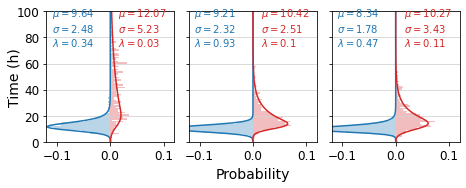

In [25]:
win = 21
pol = 2
size = (7,3)
c1 = "tab:blue"
c2 = "tab:red"
xmin = -0.12
xmax = 0.12
ymin = 0
ymax = 100

fig, axes = plt.subplots(1, 3, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)


h, edges =np.histogram(g1_dmso_1, bins=range(0,101), density=True)
out = axes[0].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[0].plot(fitted_curve, centers, color=c1)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)
h, edges =np.histogram(g1_erl_1, bins=range(0,101), density=True)
out = axes[0].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0].plot(fitted_curve, centers, color=c2)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)


h, edges =np.histogram(g1_dmso_2, bins=range(0,101), density=True)
out = axes[1].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[1].plot(fitted_curve, centers, color=c1)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)
h, edges =np.histogram(g1_erl_2, bins=range(0,101), density=True)
out = axes[1].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1].plot(fitted_curve, centers, color=c2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)


h, edges =np.histogram(g1_dmso_3, bins=range(0,101), density=True)
out = axes[2].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[2].plot(fitted_curve, centers, color=c1)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)
h, edges =np.histogram(g1_erl_3, bins=range(0,101), density=True)
out = axes[2].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[2].plot(fitted_curve, centers, color=c2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)


ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Probability', labelpad=25)
ax.set_ylabel('Time (h)', labelpad=25)
#fig.tight_layout(rect=(0, 0, 1, 1))
plt.savefig('C:\\Users\Austin\Documents\\UMAP_projects\\nsclc_model\\fig1b_mod.svg', bbox_inches='tight')